# 04 Shared and coordinated PPO

Alpha sweep for coordinated PPO on `grid4x4`. The sweep file is `configs/sweeps/alpha_grid4x4.yaml`: method `coordinated_ppo`, alpha `{0, 0.25, 0.5, 0.75}`, train seeds 0–4, and **300 episodes**. Notebook 01 timed one random `grid4x4` episode at 55.58 s with TraCI and 2.64 s with libsumo, so 300 episodes are 4.63 h or 0.22 h. That fits the 8-hour SLURM task, which runs under libsumo.

The figures read whatever training curves and evaluation tables are already on disk. Full 300-episode curves replace the shorter alpha-selection curves when both exist. Validation scores come from `configs/frozen.yaml`, which was filled on validation route seeds 5–9 only.

In [1]:
%matplotlib inline
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy import stats

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

RAW = ROOT / "results" / "raw"
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SCENARIO = "grid4x4"
ALPHAS = (0.0, 0.25, 0.5, 0.75)
ALPHA_COLORS = {0.0: "#0072B2", 0.25: "#009E73", 0.5: "#E69F00", 0.75: "#D55E00"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3})


def mean_ci(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    n = len(values)
    if n == 0:
        return np.nan, np.nan, 0
    mean = float(values.mean())
    if n < 2:
        return mean, np.nan, n
    half = float(stats.t.ppf((1 + confidence) / 2, n - 1) * values.std(ddof=1) / np.sqrt(n))
    return mean, half, n

## Learning curves

Each curve is mean system waiting time during training. The band is a 95% t interval across train seeds at that episode. One seed leaves the band out.

alpha selection curves: 1 seed(s), alphas [0.0, 0.25, 0.5, 0.75], 8 episodes


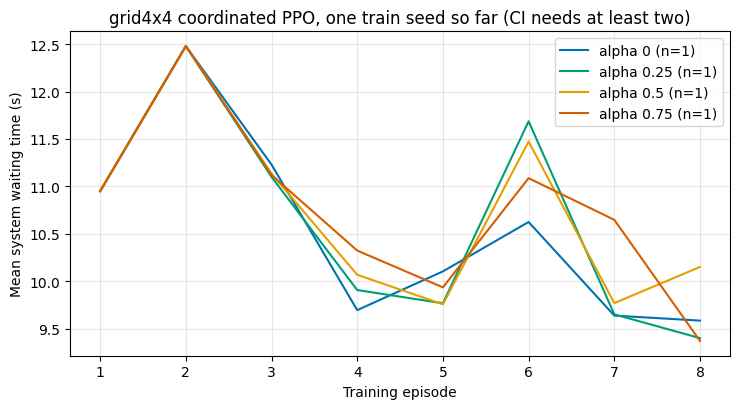

In [2]:
FULL_CURVE = re.compile(
    rf"coordinated_ppo_{SCENARIO}_obs_on_alpha(?P<alpha>\d+(?:\.\d+)?)_seed(?P<seed>\d+)\.csv"
)
SELECTION_CURVE = re.compile(
    rf"alpha_selection_{SCENARIO}_alpha(?P<alpha>\d+(?:\.\d+)?)_seed(?P<seed>\d+)\.csv"
)


def load_curves(pattern, source):
    frames = []
    for path in sorted((RAW / "train_curves").glob(pattern)):
        match = FULL_CURVE.search(path.name) or SELECTION_CURVE.search(path.name)
        if match is None:
            continue
        frame = pd.read_csv(path)
        frame["alpha"] = float(match.group("alpha"))
        frame["seed"] = int(match.group("seed"))
        frame["source"] = source
        frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


curves = load_curves(f"coordinated_ppo_{SCENARIO}_obs_on_alpha*_seed*.csv", "training")
if curves.empty:
    curves = load_curves(f"alpha_selection_{SCENARIO}_alpha*_seed*.csv", "alpha selection")

if curves.empty:
    print("No coordinated PPO curves for grid4x4 yet.")
else:
    print(
        f"{curves['source'].iloc[0]} curves: "
        f"{curves['seed'].nunique()} seed(s), "
        f"alphas {sorted(float(value) for value in curves['alpha'].unique())}, "
        f"{int(curves['episode'].max())} episodes"
    )
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for alpha in ALPHAS:
        block = curves[np.isclose(curves["alpha"], alpha)]
        if block.empty:
            continue
        rows = []
        for episode, group in block.groupby("episode"):
            mean, half, n = mean_ci(group["mean_system_waiting_time"])
            rows.append({"episode": episode, "mean": mean, "half": half, "n": n})
        summary = pd.DataFrame(rows).sort_values("episode")
        n_seeds = int(summary["n"].max())
        ax.plot(
            summary["episode"],
            summary["mean"],
            color=ALPHA_COLORS[alpha],
            label=f"alpha {alpha:g} (n={n_seeds})",
        )
        if summary["half"].notna().any():
            ax.fill_between(
                summary["episode"],
                summary["mean"] - summary["half"],
                summary["mean"] + summary["half"],
                color=ALPHA_COLORS[alpha],
                alpha=0.2,
            )
    n_seeds = int(curves["seed"].nunique())
    title = "grid4x4 coordinated PPO, mean ± 95% CI across train seeds"
    if n_seeds < 2:
        title = "grid4x4 coordinated PPO, one train seed so far (CI needs at least two)"
    ax.set_xlabel("Training episode")
    ax.set_ylabel("Mean system waiting time (s)")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG / "04_learning_curves_by_alpha.png")
    plt.show()

## Validation waiting time vs alpha

`configs/frozen.yaml` stores the mean waiting time on the validation route seeds. Test seeds are not in this file.

scenario=grid4x4 train_seed=0 episodes=8 validation_seeds=[5, 6, 7, 8, 9]


,alpha,avg_waiting_time
0,0.00,376.074397
1,0.25,345.737686
2,0.50,289.332581
3,0.75,182.396164


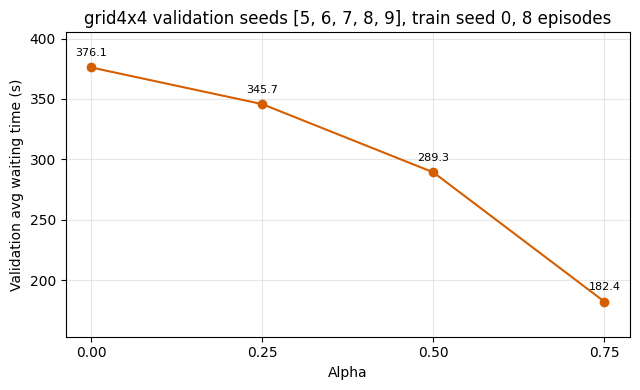

In [3]:
frozen = yaml.safe_load((ROOT / "configs" / "frozen.yaml").read_text())
validation = pd.DataFrame(frozen["scores"]).sort_values("alpha")
print(
    f"scenario={frozen['scenario']} train_seed={frozen['train_seed']} "
    f"episodes={frozen['episodes']} validation_seeds={frozen['validation_seeds']}"
)
display(validation)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(validation["alpha"], validation["avg_waiting_time"], marker="o", color="#D55E00")
for _, row in validation.iterrows():
    ax.annotate(
        f"{row['avg_waiting_time']:.1f}",
        (row["alpha"], row["avg_waiting_time"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )
low = float(validation["avg_waiting_time"].min())
high = float(validation["avg_waiting_time"].max())
pad = (high - low) * 0.15
ax.set_ylim(low - pad, high + pad)
ax.set_xticks(list(ALPHAS))
ax.set_xlabel("Alpha")
ax.set_ylabel("Validation avg waiting time (s)")
ax.set_title(
    f"grid4x4 validation seeds {frozen['validation_seeds']}, "
    f"train seed {frozen['train_seed']}, {frozen['episodes']} episodes"
)
fig.tight_layout()
fig.savefig(FIG / "04_validation_waiting_time_vs_alpha.png")
plt.show()

## Shared PPO vs coordinated PPO

Bars use the evaluation tables `results/raw/grid4x4/default/shared_ppo.csv` and `coordinated_ppo.csv`. The height is the mean waiting time. With more than one train seed, the interval is a 95% CI across train seeds; otherwise it is across the test seeds of the single run.

In [4]:
eval_dir = RAW / SCENARIO / "default"
frames = []
for method in ("shared_ppo", "coordinated_ppo"):
    path = eval_dir / f"{method}.csv"
    if path.is_file():
        frames.append(pd.read_csv(path))
    else:
        print(f"missing {path.relative_to(ROOT)}")

if not frames:
    print("No grid4x4 evaluation tables yet, so the comparison bar chart waits for those runs.")
else:
    evaluated = pd.concat(frames, ignore_index=True)
    evaluated = evaluated[evaluated["scenario"] == SCENARIO]
    labels = {"shared_ppo": "Shared PPO", "coordinated_ppo": "Coordinated PPO"}
    colors = {"shared_ppo": "#0072B2", "coordinated_ppo": "#D55E00"}
    means, halves, names, bar_colors = [], [], [], []
    for method in ("shared_ppo", "coordinated_ppo"):
        block = evaluated[evaluated["method"] == method]
        if block.empty:
            continue
        if block["train_seed"].nunique() > 1:
            units = block.groupby("train_seed")["avg_waiting_time"].mean()
        else:
            units = block["avg_waiting_time"]
        mean, half, n = mean_ci(units)
        means.append(mean)
        halves.append(0.0 if np.isnan(half) else half)
        names.append(f"{labels[method]}\n(n={n})")
        bar_colors.append(colors[method])
        print(f"{method}: mean waiting time {mean:.2f} s, 95% half-width {half}, n={n}")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(names, means, yerr=halves, color=bar_colors, capsize=4)
    ax.set_ylabel("Avg waiting time (s)")
    ax.set_title("grid4x4 shared PPO vs coordinated PPO")
    fig.tight_layout()
    fig.savefig(FIG / "04_shared_vs_coordinated.png")
    plt.show()

missing results/raw/grid4x4/default/shared_ppo.csv
missing results/raw/grid4x4/default/coordinated_ppo.csv
No grid4x4 evaluation tables yet, so the comparison bar chart waits for those runs.
